# Module 1 · One Line, Then Many
**Verse 1 + pre-chorus "DEPTH" · 0:00–0:45**

The song opens with a pen plotter drawing a single line: y = 0, the first baseline. This module goes from that line to a deep convolutional network, one replacement at a time, just as the verse does:

perceptron → XOR → hidden layer + backprop → sigmoid's vanishing gradient → ReLU → hand-made features (HOG) → SVM and kernels → learned filters (CNN) → depth via residual connections.

It uses Module 0's pieces throughout: the training loop, classification with cross-entropy, and mini-batches.



In [1]:
import sys; sys.path.insert(0, '.')
from blcourse import *
import matplotlib.pyplot as plt
hardware_report()



python 3.11.15 · torch 2.15.0 · arm64 · 64 GB RAM
DEVICE = 'mps'   TIER = 'laptop'   (override: BASELINE_TIER / BASELINE_DEVICE)


<hr style="height:4px;border:0;background:#888;margin:2em 0 1em">

## 1.1 The perceptron draws a line (1958)



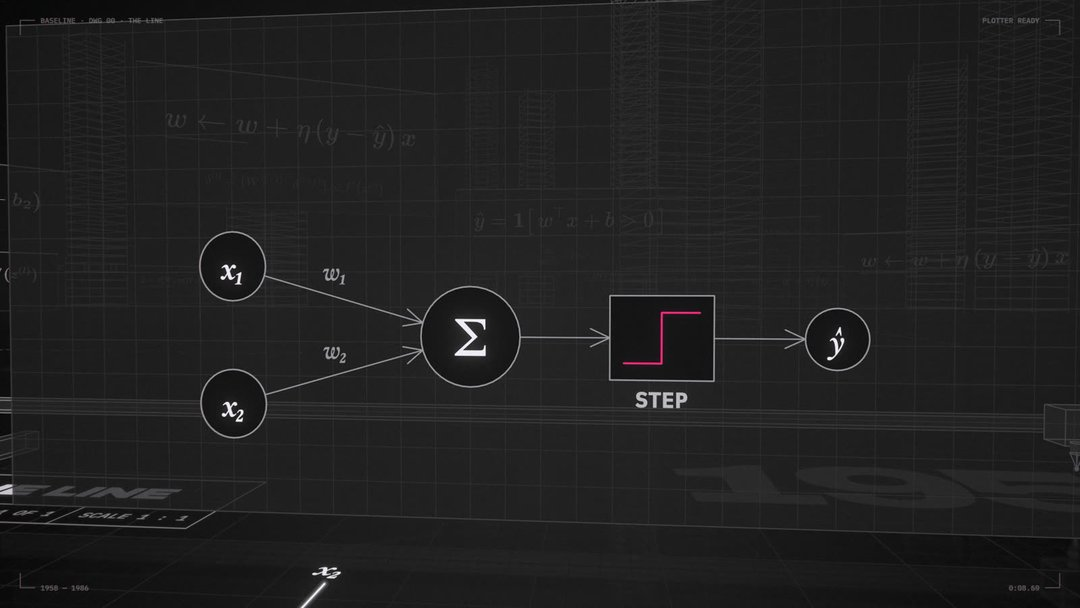

In [2]:
still(8.6)



A perceptron computes ŷ = step(w·x + b). Geometrically, w·x + b = 0 is a **line** (in more dimensions, a hyperplane). Everything on one side is class 1, everything on the other side is class 0. Rosenblatt's learning rule nudges the line toward every point it gets wrong:

$$w \leftarrow w + \eta\,(y - \hat y)\,x$$

Let's train it on three Boolean functions.



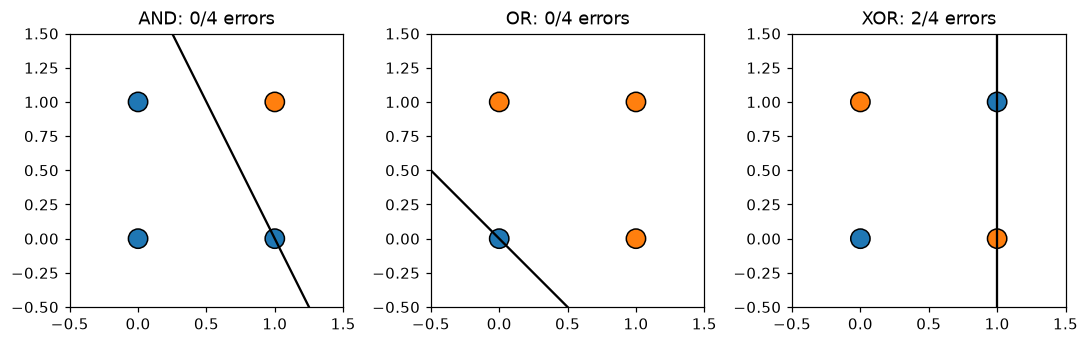

In [3]:
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
TARGETS = {'AND': [0, 0, 0, 1], 'OR': [0, 1, 1, 1], 'XOR': [0, 1, 1, 0]}

def perceptron(y, epochs=25, lr=0.1):
    w, b = np.zeros(2), 0.0
    for _ in range(epochs):
        for xi, yi in zip(X, y):
            yhat = float(w @ xi + b > 0)
            w, b = w + lr * (yi - yhat) * xi, b + lr * (yi - yhat)
    errors = int(sum(float(w @ xi + b > 0) != yi for xi, yi in zip(X, y)))
    return w, b, errors

fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
for ax, (name, y) in zip(axes, TARGETS.items()):
    w, b, err = perceptron(np.array(y, float))
    ax.scatter(*X.T, c=['C1' if t else 'C0' for t in y], s=160, edgecolors='k')
    xs = np.linspace(-0.5, 1.5, 2)
    if abs(w[1]) > 1e-9:
        ax.plot(xs, -(w[0] * xs + b) / w[1], c='k')
    elif abs(w[0]) > 1e-9:
        ax.axvline(-b / w[0], c='k')
    ax.set(xlim=(-0.5, 1.5), ylim=(-0.5, 1.5), title=f'{name}: {err}/4 errors', aspect='equal')
plt.tight_layout()



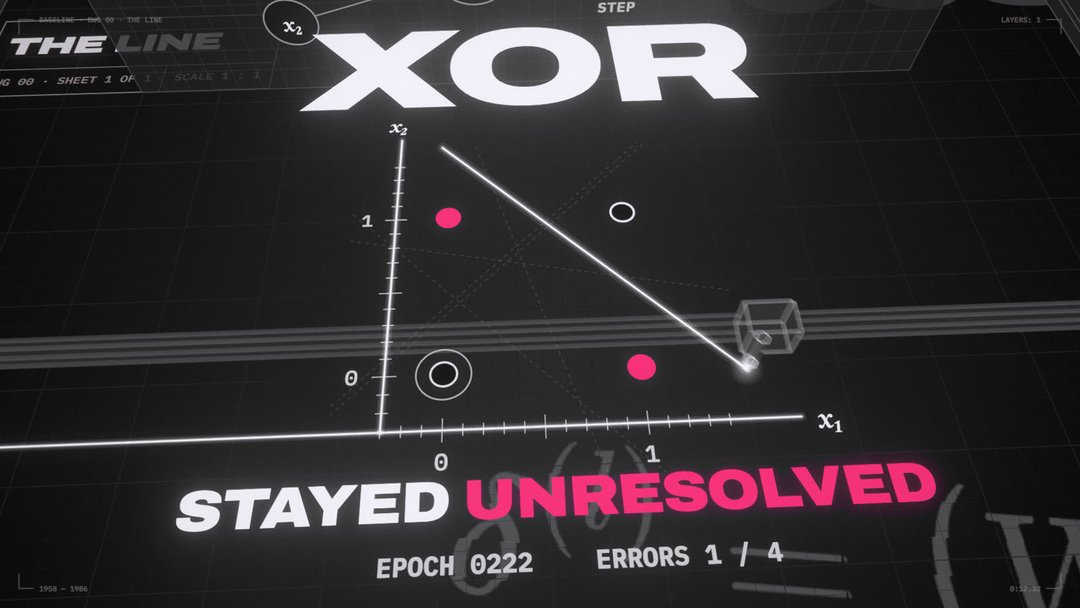

In [4]:
still(12.33)



**XOR is not linearly separable.** No single line puts (0,1) and (1,0) on one side and (0,0) and (1,1) on the other. The best any line can do is 3/4. Minsky and Papert's 1969 book made this limitation famous.



### Your turn: the update rule
Write one perceptron learning step: predict with the current line (1 if w·x + b > 0, else 0), then move w by lr × (target − prediction) × x, and b by lr × (target − prediction). The check trains AND and OR with your function for 25 epochs.



In [5]:
def perceptron_step(w, b, x, y, lr):
    """One update on input x (2 numbers) with target y (0 or 1). Return the new (w, b)."""
    raise NotImplementedError        # your code here: about 2 lines

check('perceptron_step', perceptron_step)



⏳ perceptron_step: not attempted yet. Fill in the code above and rerun this cell. (Stuck? The reference solution is in notebooks/exercises.py.)


<hr style="height:4px;border:0;background:#888;margin:2em 0 1em">

## 1.2 Stack another hidden layer, and backpropagate
Put a layer of two units between input and output. Each hidden unit draws its own line. The output unit then combines those two lines, and a combination of lines can carve out shapes that one line can't.

To train it you need ∂loss/∂(every weight), including the weights the output doesn't touch directly. **Backpropagation** (Rumelhart, Hinton & Williams, 1986) is the chain rule applied layer by layer, from the output back to the input. Here it is by hand in numpy, the same 2-2-1 sigmoid network and seed the film used:



In [6]:
sig = lambda z: 1 / (1 + np.exp(-z))
Y = np.array(TARGETS['XOR'], float)

rng = np.random.default_rng(7)
W1, b1, w2, b2 = rng.normal(0, 1, (2, 2)), rng.normal(0, 1, 2), rng.normal(0, 1, 2), rng.normal(0, 1)
v = [0, 0, 0, 0]; lr, mom = 1.0, 0.9
for epoch in range(4001):
    H = sig(X @ W1.T + b1)                  # forward: hidden layer
    yhat = sig(H @ w2 + b2)                 # forward: output
    d2 = (yhat - Y) / 4                     # backward: dL/dz2 for cross-entropy + sigmoid
    gw2, gb2 = H.T @ d2, d2.sum()
    dH = np.outer(d2, w2) * H * (1 - H)     # chain rule through the hidden sigmoid
    gW1, gb1 = dH.T @ X, dH.sum(0)
    v = [mom * vi - lr * g for vi, g in zip(v, (gW1, gb1, gw2, gb2))]
    W1, b1, w2, b2 = W1 + v[0], b1 + v[1], w2 + v[2], b2 + v[3]
print('outputs', np.round(yhat, 3), ' targets', Y)



outputs [0. 1. 1. 0.]  targets [0. 1. 1. 0.]


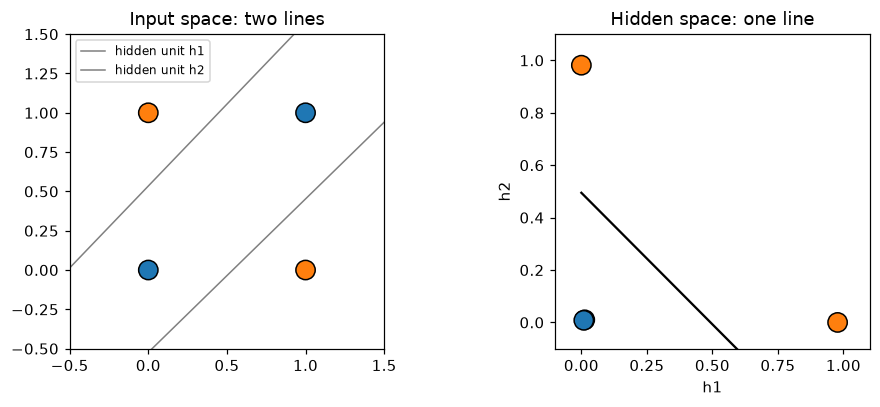

In [7]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.8))
xs = np.linspace(-0.5, 1.5, 2)
a1.scatter(*X.T, c=['C1' if t else 'C0' for t in Y], s=160, edgecolors='k')
for j in range(2):
    a1.plot(xs, -(W1[j, 0] * xs + b1[j]) / W1[j, 1], c='gray', lw=1, label=f'hidden unit h{j+1}')
a1.set(xlim=(-0.5, 1.5), ylim=(-0.5, 1.5), aspect='equal', title='Input space: two lines'); a1.legend(fontsize=8)
a2.scatter(*H.T, c=['C1' if t else 'C0' for t in Y], s=160, edgecolors='k')
hs = np.linspace(0, 1, 2)
a2.plot(hs, -(w2[0] * hs + b2) / w2[1], c='k')
a2.set(xlim=(-0.1, 1.1), ylim=(-0.1, 1.1), aspect='equal', title='Hidden space: one line', xlabel='h1', ylabel='h2')
plt.tight_layout()



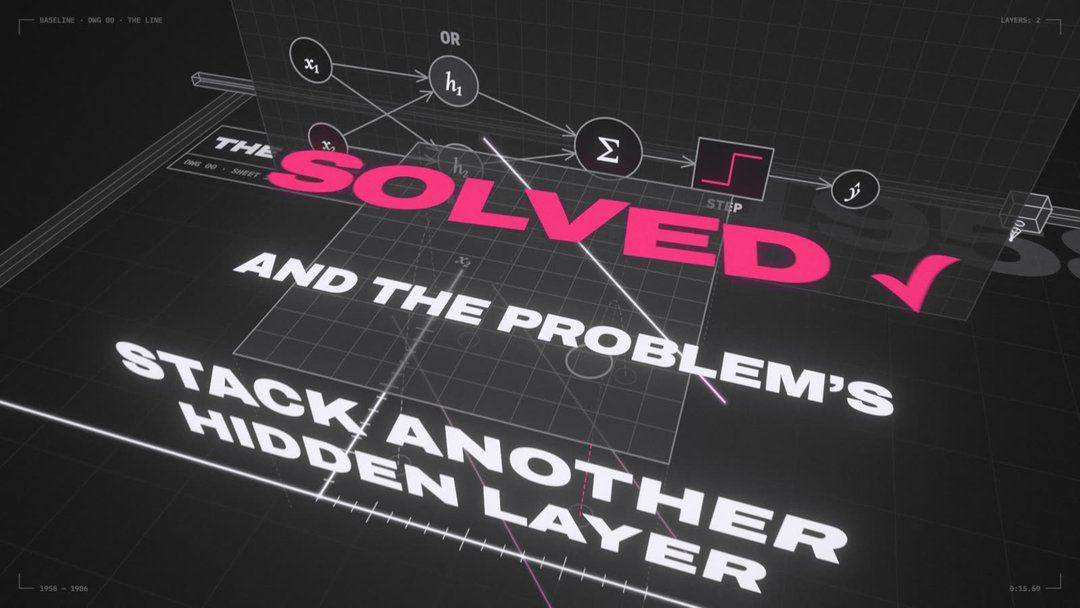

In [8]:
still(15.6)



**The key idea of deep learning, in one picture:** a hidden layer *re-represents* the data until the problem becomes linear. Every network in this course is a stack of such re-representations.



### Your turn: wire XOR by hand
Backprop *found* weights that solve XOR. Can you? Use step units (a unit outputs 1 when its weighted sum is above 0). Pick `W1` (2×2) and `b1` so hidden unit 1 computes OR and hidden unit 2 computes NAND, then `w2`, `b2` so the output is the AND of the two hidden units.

Hint: OR fires when x₁ + x₂ > 0.5, which is weights (1, 1) and bias −0.5.



In [9]:
def xor_weights():
    """Return W1 (2×2: one row per hidden unit), b1 (2 numbers), w2 (2 numbers), b2 (a number)."""
    raise NotImplementedError        # your code here

check('xor_weights', xor_weights)



⏳ xor_weights: not attempted yet. Fill in the code above and rerun this cell. (Stuck? The reference solution is in notebooks/exercises.py.)


<hr style="height:4px;border:0;background:#888;margin:2em 0 1em">

## 1.3 Sigmoid squashed the signal; ReLU clipped the negatives



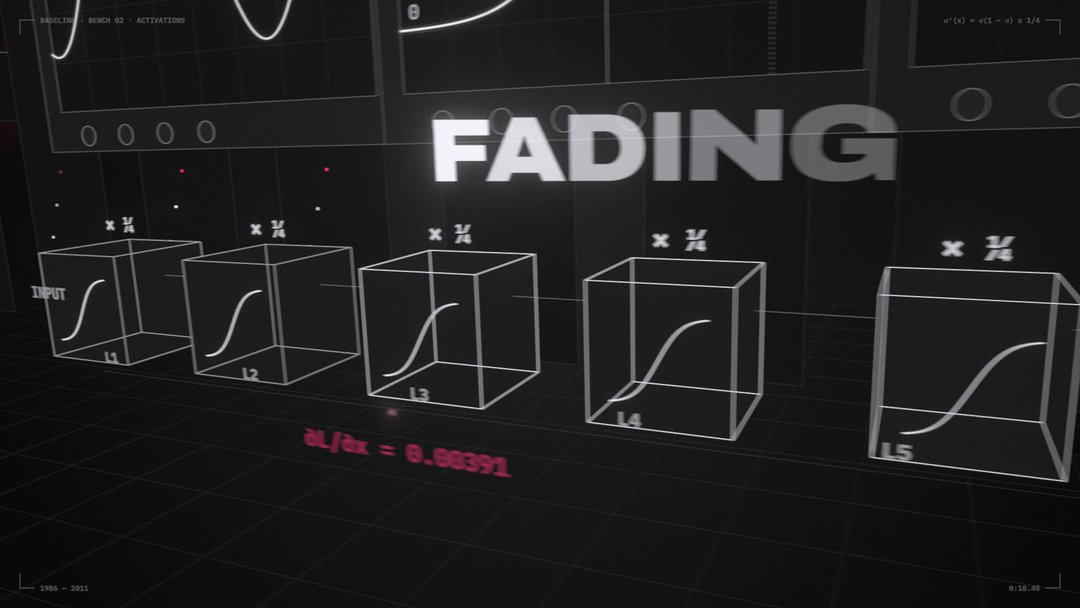

In [10]:
still(18.49)



The sigmoid's slope is at most ¼ (at x = 0). Backprop multiplies one such slope per layer. Through 8 sigmoid layers the gradient is at most (¼)⁸ ≈ 0.000015 of what it was at the output. The early layers, which are the ones that should learn the basic features, get almost no signal. This is the **vanishing gradient**.

**ReLU** = max(0, x) has slope exactly 1 for positive inputs, so the gradient passes through undiminished. AlexNet (2012) used it, and very deep networks became trainable.

Let's measure it in a real 12-layer network. Each activation gets its standard **initialization**: the random scale of the starting weights, chosen so that signals neither shrink nor blow up at the start (Xavier for sigmoid, He for ReLU). Initialization is the other half of making deep nets trainable.



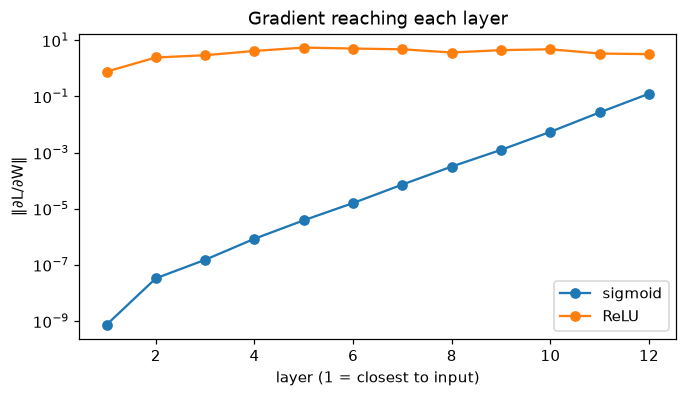

In [11]:
def grad_profile(act, depth=12, width=64):
    seed(0)
    layers = [nn.Linear(width, width) for _ in range(depth)]
    for l in layers:
        if act is torch.relu:
            nn.init.kaiming_normal_(l.weight, nonlinearity='relu')
        else:
            nn.init.xavier_normal_(l.weight)
        nn.init.zeros_(l.bias)
    h = torch.randn(256, width)
    for l in layers:
        h = act(l(h))
    h.pow(2).mean().backward()
    return [l.weight.grad.norm().item() for l in layers]

fig, ax = plt.subplots()
ax.plot(range(1, 13), grad_profile(torch.sigmoid), 'o-', label='sigmoid')
ax.plot(range(1, 13), grad_profile(torch.relu), 'o-', label='ReLU')
ax.set(yscale='log', xlabel='layer (1 = closest to input)', ylabel='‖∂L/∂W‖', title='Gradient reaching each layer'); ax.legend();



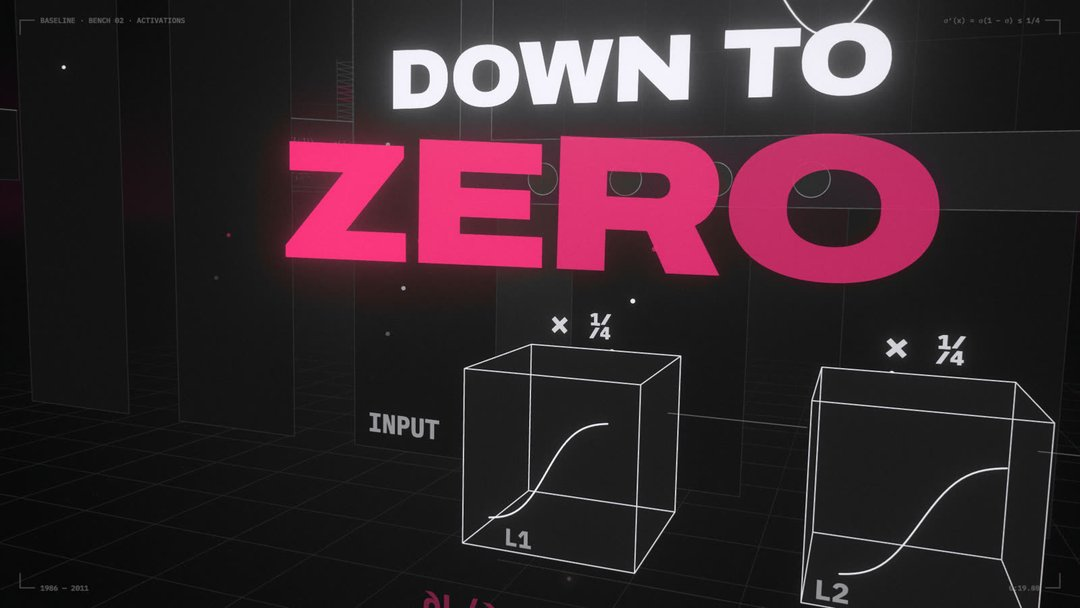

In [12]:
still(19.5)



### Try it
Swap in `torch.tanh`. Its maximum slope is 1, not ¼. Is it closer to sigmoid or to ReLU here, and why?
<details><summary>Answer</summary>

In between. tanh's slope is 1 only at exactly 0 and falls off for larger inputs, so the gradient still shrinks layer by layer, just more slowly than with sigmoid. LSTMs (Module 2) still use sigmoid and tanh internally, but in gates, not stacked deep.
</details>



<hr style="height:4px;border:0;background:#888;margin:2em 0 1em">

## 1.4 Every feature carved by hand (1999–2005)



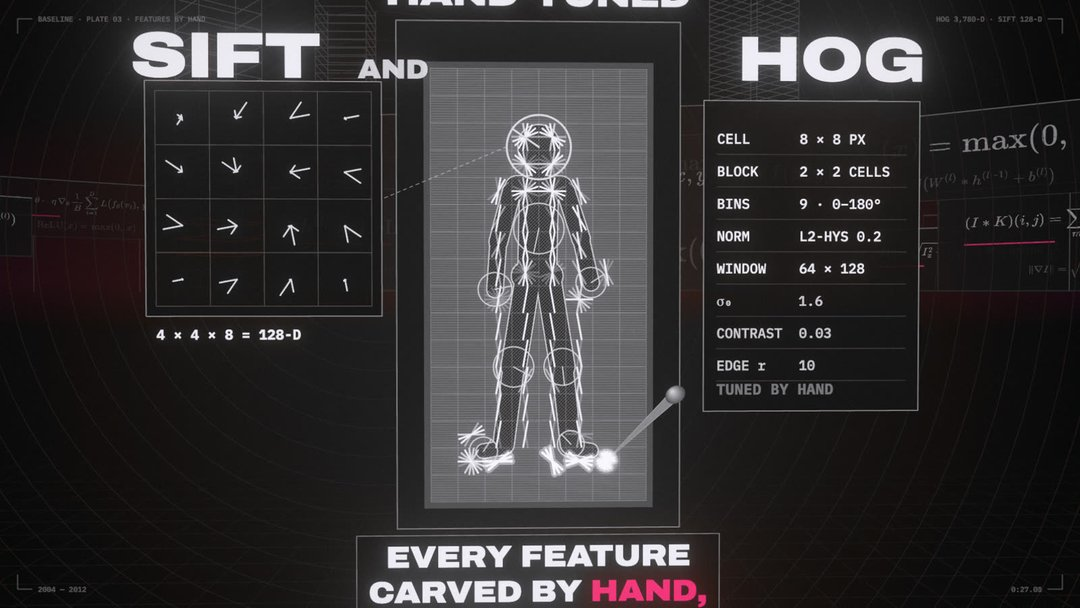

In [13]:
still(27.01)



Before 2012, computer vision meant **feature engineering**. Experts designed descriptors like SIFT (1999) and HOG (2005), histograms of edge directions in small cells, and fed them to a classifier such as an SVM. Then convolutional networks learned their own features from the pixels and beat them.

Let's run that contest on CIFAR-10 (60,000 32×32 photos, 10 classes). The download is about 140 MB on first run.



train (20000, 32, 32, 3), test (10000, 32, 32, 3)


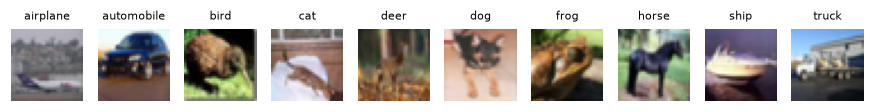

In [14]:
train_x, train_y, Xte_u8, yte = cifar10()
CLASSES = CIFAR10_CLASSES
n = CFG['cifar_train']
Xtr_u8, ytr = train_x[:n], train_y[:n]
print(f'train {Xtr_u8.shape}, test {Xte_u8.shape}')

fig, axes = plt.subplots(1, 10, figsize=(10, 1.4))
for ax, c in zip(axes, range(10)):
    ax.imshow(Xtr_u8[np.where(ytr == c)[0][0]]); ax.set_title(CLASSES[c], fontsize=7); ax.axis('off')



### HOG, written out
compute each pixel's gradient direction and strength, then for every 8×8 cell build a 9-bin histogram of directions weighted by strength. You get 4×4 cells × 9 bins = 144 numbers per image. We add a coarse 4×4 color thumbnail (48 numbers), since HOG ignores color.



In [15]:
def hog(imgs_u8):
    g = imgs_u8.astype(np.float32).mean(-1) / 255           # grayscale, N×32×32
    gx, gy = np.zeros_like(g), np.zeros_like(g)
    gx[:, :, 1:-1] = g[:, :, 2:] - g[:, :, :-2]
    gy[:, 1:-1, :] = g[:, 2:, :] - g[:, :-2, :]
    mag = np.hypot(gx, gy)
    bins = ((np.degrees(np.arctan2(gy, gx)) % 180) // 20).astype(int).clip(0, 8)
    N = len(g)
    m = mag.reshape(N, 4, 8, 4, 8).transpose(0, 1, 3, 2, 4).reshape(N, 16, 64)
    b = bins.reshape(N, 4, 8, 4, 8).transpose(0, 1, 3, 2, 4).reshape(N, 16, 64)
    H = np.stack([(m * (b == k)).sum(-1) for k in range(9)], -1).reshape(N, -1)
    H /= np.linalg.norm(H, axis=1, keepdims=True) + 1e-6
    color = imgs_u8.reshape(N, 4, 8, 4, 8, 3).mean((2, 4)).reshape(N, -1) / 255
    return np.hstack([H, color])



<hr style="height:4px;border:0;background:#888;margin:2em 0 1em">

## 1.5 SVM: the widest margin, and the kernel trick
Among all lines that separate two classes, the **support vector machine** (Cortes & Vapnik, 1995) picks the one with the widest empty street on both sides. The points on the curbs are the **support vectors**. Only those points determine the line.



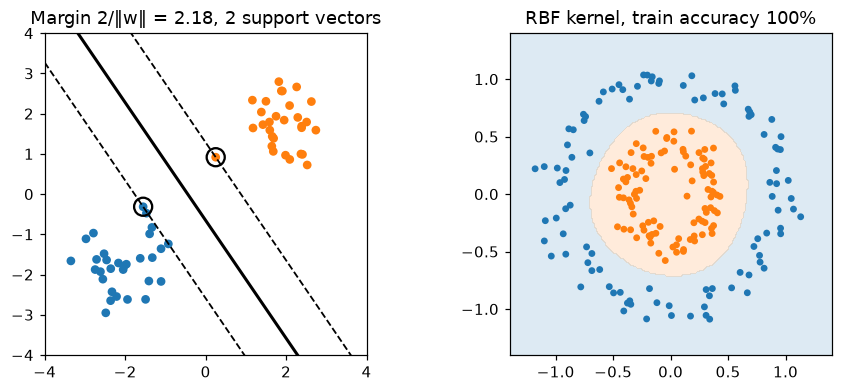

In [16]:
from sklearn.svm import SVC
from sklearn.datasets import make_blobs, make_circles
Xb, yb = make_blobs(60, centers=[(-2, -1.5), (2, 1.5)], cluster_std=0.6, random_state=3)
lin = SVC(kernel='linear', C=1e3).fit(Xb, yb)
w, b = lin.coef_[0], lin.intercept_[0]
xs = np.linspace(-4, 4, 2)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.8))
a1.scatter(*Xb.T, c=['C1' if t else 'C0' for t in yb], s=22)
for off, st in ((0, '-'), (1, '--'), (-1, '--')):
    a1.plot(xs, -(w[0] * xs + b - off) / w[1], st, c='k', lw=1.2 if off else 2)
a1.scatter(*lin.support_vectors_.T, s=140, facecolors='none', edgecolors='k', lw=1.5)
a1.set(xlim=(-4, 4), ylim=(-4, 4), aspect='equal', title=f'Margin 2/‖w‖ = {2 / np.linalg.norm(w):.2f}, {len(lin.support_vectors_)} support vectors')

Xc, yc = make_circles(200, factor=0.4, noise=0.08, random_state=0)
rbf = SVC(kernel='rbf', C=10).fit(Xc, yc)
gx, gy = np.meshgrid(np.linspace(-1.4, 1.4, 200), np.linspace(-1.4, 1.4, 200))
a2.contourf(gx, gy, rbf.decision_function(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape) > 0, levels=1, colors=['C0', 'C1'], alpha=0.15)
a2.scatter(*Xc.T, c=['C1' if t else 'C0' for t in yc], s=12)
a2.set(aspect='equal', title=f'RBF kernel, train accuracy {rbf.score(Xc, yc):.0%}');



The rings on the right can't be separated by any line. The **kernel trick** separates them by implicitly mapping the points into more dimensions. The film uses the explicit version: lift each point by φ(x) = (x₁, x₂, x₁² + x₂²). The inner ring now sits lower than the outer one, and a flat plane cuts between them.



Text(0.5, 0.92, 'φ(x) = (x₁, x₂, x₁² + x₂²)')

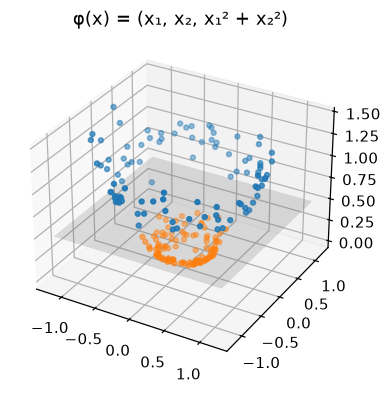

In [17]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
z = (Xc ** 2).sum(1)
ax = plt.figure(figsize=(5, 4)).add_subplot(projection='3d')
ax.scatter(Xc[:, 0], Xc[:, 1], z, c=['C1' if t else 'C0' for t in yc], s=10)
pp = np.linspace(-1.2, 1.2, 2); P1, P2 = np.meshgrid(pp, pp)
ax.plot_surface(P1, P2, np.full_like(P1, 0.5), color='gray', alpha=0.2)
ax.set_title('φ(x) = (x₁, x₂, x₁² + x₂²)')



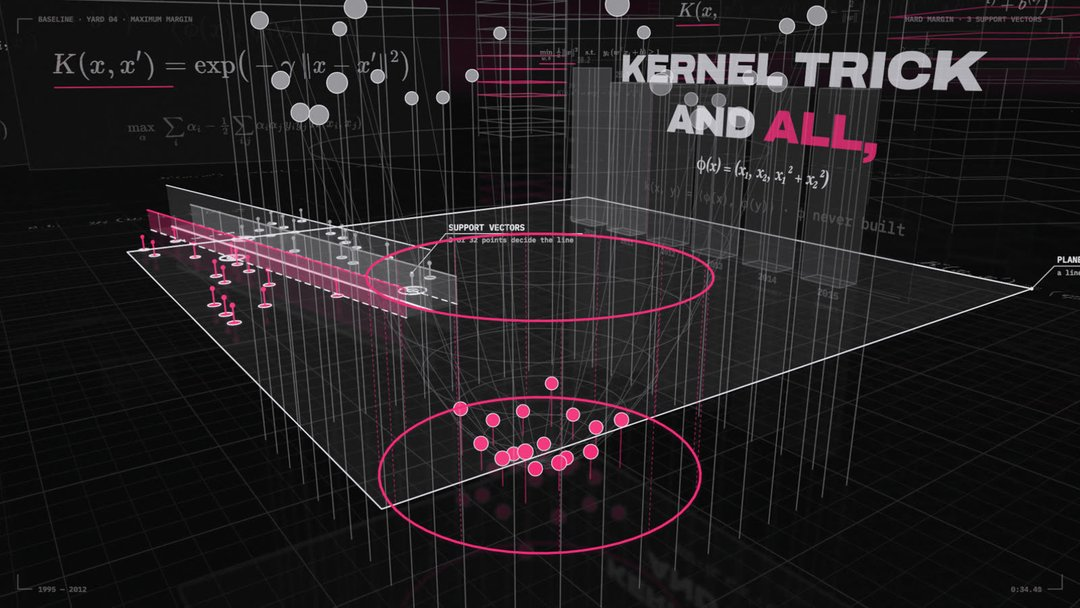

In [18]:
still(34.41)



### The 2005 recipe: HOG features + a linear SVM, on real photos
Now put the two halves together the way a 2005 vision system would: the HOG features from §1.4 go into a linear SVM.

> **Predict first.** CIFAR-10 has 10 classes, so guessing scores 10%. What accuracy will hand-made features plus a linear SVM reach? Write a number down before running the cell.



In [19]:
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
with timer('HOG + linear SVM:'):
    sc = StandardScaler().fit(hog(Xtr_u8))
    svm = LinearSVC(C=0.05, max_iter=5000).fit(sc.transform(hog(Xtr_u8)), ytr)
    acc_hog = (svm.predict(sc.transform(hog(Xte_u8))) == yte).mean()
print(f'HOG + SVM test accuracy: {acc_hog:.1%}   (chance: 10%)')



HOG + linear SVM: 15.23s
HOG + SVM test accuracy: 55.8%   (chance: 10%)


<hr style="height:4px;border:0;background:#888;margin:2em 0 1em">

## 1.6 Learned filters nobody planned (2012)
Now the 2012 recipe: let a convolutional network learn its own features from the pixels.

### The convolution
A **convolution** slides a small learned filter (here 5×5×3) over the image and records how strongly each location matches it. The first layer's filters are just weights, initialized randomly. Training shapes them into whatever detectors help reduce the loss.

On the `mac-max`/`cuda` tiers the network gets wider and adds **residual blocks** (section 1.7).

The training loop below is Module 0's loop at scale (§0.5): shuffled mini-batches, epochs, AdamW with a learning-rate schedule, random flips as augmentation, and `eval()` mode for scoring. The loss is the cross-entropy from §0.4.

> **Predict first.** HOG + SVM just scored `acc_hog`. Will a small CNN trained for a few minutes beat it, and by how much? Compare once the cell finishes.



In [20]:
class ResBlock(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.f = nn.Sequential(nn.Conv2d(c, c, 3, padding=1, bias=False), nn.BatchNorm2d(c), nn.ReLU(),
                               nn.Conv2d(c, c, 3, padding=1, bias=False), nn.BatchNorm2d(c))
    def forward(self, x):
        return F.relu(x + self.f(x))

def make_cnn(w, residual):
    return nn.Sequential(
        nn.Conv2d(3, w, 5, padding=2), nn.BatchNorm2d(w), nn.ReLU(), nn.MaxPool2d(2),                       # conv1: 32→16
        nn.Conv2d(w, 2 * w, 3, padding=1), nn.BatchNorm2d(2 * w), nn.ReLU(),
        *([ResBlock(2 * w)] if residual else []), nn.MaxPool2d(2),                                          # 16→8
        nn.Conv2d(2 * w, 4 * w, 3, padding=1), nn.BatchNorm2d(4 * w), nn.ReLU(),
        *([ResBlock(4 * w)] if residual else []),
        nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(4 * w, 10))

MEAN = torch.tensor([0.49, 0.48, 0.45]).view(1, 3, 1, 1); STD = torch.tensor([0.25, 0.24, 0.26]).view(1, 3, 1, 1)
to_t = lambda a: ((torch.tensor(a).permute(0, 3, 1, 2).float() / 255) - MEAN) / STD
Xtr, Xte = to_t(Xtr_u8), to_t(Xte_u8)
Ytr, Yte = torch.tensor(ytr), torch.tensor(yte)

seed(0)
cnn = make_cnn(CFG['cnn_width'], CFG['resnet']).to(DEVICE)
with torch.no_grad():
    cnn[0].weight.mul_(0.1)                                   # start conv1's filters small: see "Look at what it learned"
print(f'CNN: {n_params(cnn):,} parameters')
epochs, bs = CFG['cifar_epochs'], 128
opt = torch.optim.AdamW(cnn.parameters(), lr=3e-3, weight_decay=5e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, 3e-3, total_steps=epochs * (len(Xtr) // bs))
snapshots = [cnn[0].weight.detach().cpu().clone()]

@torch.no_grad()
def accuracy(model, X, Y):
    model.eval()
    correct = sum((model(X[i:i + 1000].to(DEVICE)).argmax(1).cpu() == Y[i:i + 1000]).sum().item() for i in range(0, len(X), 1000))
    model.train(); return correct / len(X)

with timer('CNN training:'):
    for ep in range(epochs):
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr) - bs + 1, bs):
            idx = perm[i:i + bs]
            xb = Xtr[idx]
            flip = torch.rand(len(xb)) < 0.5                      # augmentation: random horizontal flips
            xb[flip] = xb[flip].flip(-1)
            loss = F.cross_entropy(cnn(xb.to(DEVICE)), Ytr[idx].to(DEVICE))
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        snapshots.append(cnn[0].weight.detach().cpu().clone())
        print(f'epoch {ep + 1}/{epochs}  loss {loss.item():.3f}  test acc {accuracy(cnn, Xte, Yte):.1%}')
acc_cnn = accuracy(cnn, Xte, Yte)
print(f'\nHOG + SVM {acc_hog:.1%}   vs   CNN {acc_cnn:.1%}')



CNN: 96,522 parameters


epoch 1/8  loss 1.667  test acc 40.0%


epoch 2/8  loss 1.586  test acc 38.2%


epoch 3/8  loss 1.276  test acc 42.2%


epoch 4/8  loss 1.191  test acc 55.1%


epoch 5/8  loss 0.971  test acc 59.0%


epoch 6/8  loss 1.008  test acc 63.2%


epoch 7/8  loss 0.957  test acc 67.4%


epoch 8/8  loss 0.724  test acc 68.0%
CNN training: 12.51s

HOG + SVM 55.8%   vs   CNN 68.0%


### Look at what it learned
These are the CNN's first-layer filters: random noise before training (left) and after training (right). Each square is one 5×5 filter, its three input channels drawn as red, green and blue. Nobody designed the edges, stripes and color blobs that appear on the right.

One detail makes them easier to see. The training cell started conv1's weights at a tenth of PyTorch's default size. The BatchNorm right after conv1 rescales its output anyway, so this changes nothing the network can compute; it only means less of the random starting pattern is left in the picture. At the default size, a few epochs leave the filters looking much like the left panel.



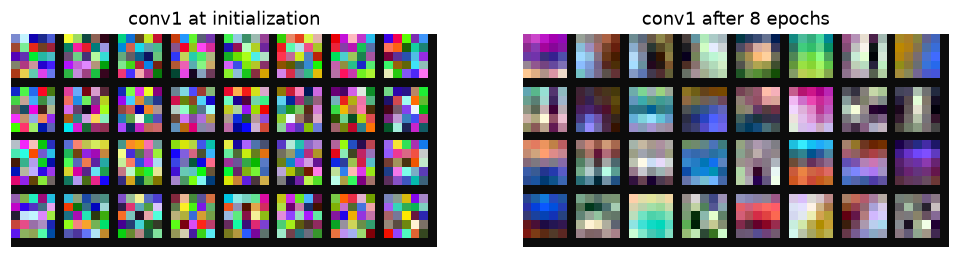

In [21]:
def filter_grid(Wt, cols=8):
    Wt = Wt[: (len(Wt) // cols) * cols]
    Wt = (Wt - Wt.amin((1, 2, 3), keepdim=True)) / (Wt.amax((1, 2, 3), keepdim=True) - Wt.amin((1, 2, 3), keepdim=True) + 1e-8)
    k = Wt.shape[-1]; rows = len(Wt) // cols
    g = torch.ones(rows * (k + 1), cols * (k + 1), 3) * 0.05
    for i, f in enumerate(Wt):
        r, c = divmod(i, cols); g[r * (k + 1):r * (k + 1) + k, c * (k + 1):c * (k + 1) + k] = f.permute(1, 2, 0)
    return g

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 5.6))
a1.imshow(filter_grid(snapshots[0]), interpolation='nearest'); a1.set_title('conv1 at initialization'); a1.axis('off')
a2.imshow(filter_grid(snapshots[-1]), interpolation='nearest'); a2.set_title(f'conv1 after {epochs} epochs'); a2.axis('off');



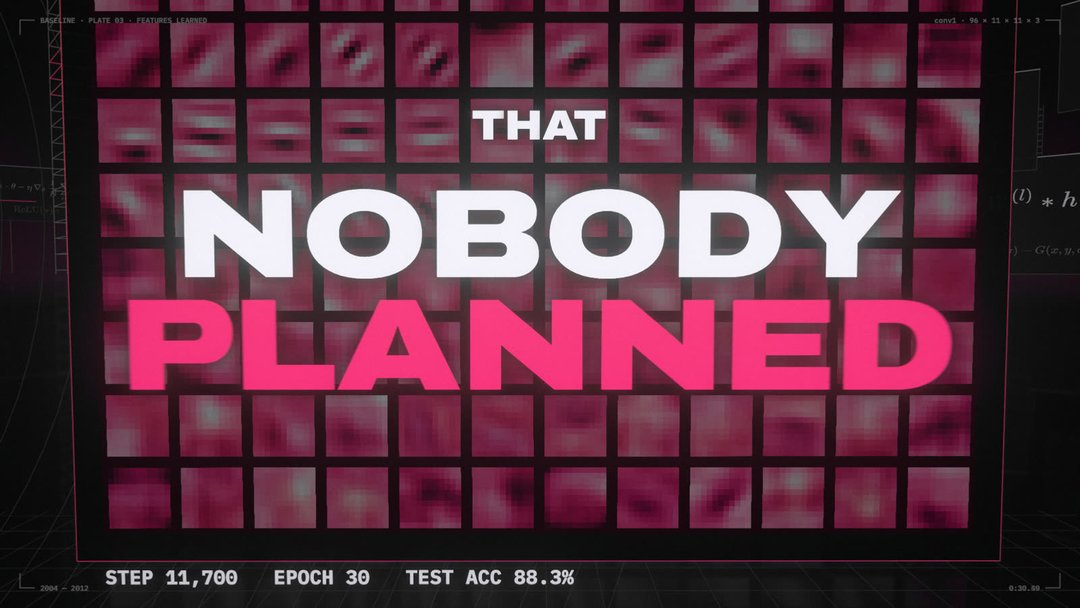

In [22]:
still(30.5)



### What the filters respond to
A 5×5 square of colors is hard to read. It's easier to run a filter over a photo and see where it responds. HOG (§1.4) found edges with two hand-written filters: the difference between a pixel's right and left neighbors, which is large on vertical edges, and between the pixels below and above, which is large on horizontal ones. The cell below finds the learned filter whose brightness pattern (its three color channels added up) best matches a dark-to-light step in each of those two directions, then runs all four filters over one test photo.



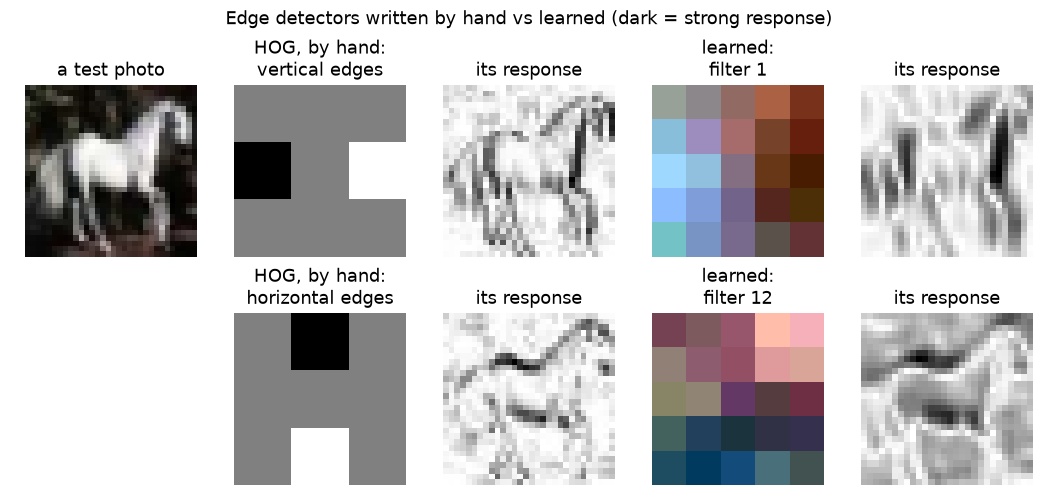

In [23]:
def edge(theta, k):
    """A k×k step from dark to light across the direction theta (degrees)."""
    c = torch.arange(k) - k // 2
    yy, xx = torch.meshgrid(c, c, indexing='ij')
    return torch.tanh(2 * (xx * math.cos(math.radians(theta)) + yy * math.sin(math.radians(theta))))

W1 = cnn[0].weight.detach().cpu()
k = W1.shape[-1]
B = W1.sum(1); B = B - B.mean((1, 2), keepdim=True)                     # each filter's brightness pattern

def most_like(T):
    """The learned filter whose brightness pattern best matches T. Dividing by the whole filter's size ranks mostly-color filters low."""
    return ((B * T).sum((1, 2)).abs() / (W1.flatten(1).std(1) * T.norm())).argmax().item()

img = Xte_u8[np.where(yte == 7)[0][0]]                                      # the first horse in the test set
gray = torch.tensor(img.mean(-1) / 255, dtype=torch.float32)[None, None]    # HOG's input: brightness, 0 to 1
dx = torch.tensor([[0., 0, 0], [-1, 0, 1], [0, 0, 0]])                      # HOG's gx from §1.4: right neighbor − left
rows = [('vertical', dx, most_like(edge(0, k))), ('horizontal', dx.T, most_like(edge(90, k)))]

fig, axs = plt.subplots(2, 5, figsize=(9.5, 4.4), layout='constrained')
axs[0, 0].imshow(img); axs[0, 0].set_title('a test photo')
for r, (name, hand, i) in enumerate(rows):
    f = W1[i]; f = (f - f.min()) / (f.max() - f.min())
    axs[r, 1].imshow(hand, cmap='gray', vmin=-1, vmax=1); axs[r, 1].set_title(f'HOG, by hand:\n{name} edges')
    axs[r, 2].imshow(F.conv2d(gray, hand[None, None])[0, 0].abs(), cmap='gray_r'); axs[r, 2].set_title('its response')
    axs[r, 3].imshow(f.permute(1, 2, 0), interpolation='nearest'); axs[r, 3].set_title(f'learned:\nfilter {i}')
    axs[r, 4].imshow(F.conv2d(to_t(img[None]), W1[i:i + 1])[0, 0].abs(), cmap='gray_r'); axs[r, 4].set_title('its response')
for a in axs.flat: a.axis('off')
fig.suptitle('Edge detectors written by hand vs learned (dark = strong response)');



Each learned filter responds to the same edges as its hand-written counterpart: the legs light up for vertical edges, the back and belly for horizontal ones. Its response is a little blurrier, because it is 5×5 rather than 3 pixels across. Nobody wrote these filters. They appeared because finding edges helped reduce the loss, and the color blobs beside them do the job of the color thumbnail we had to bolt onto HOG by hand.

**Why did deep nets win?** Both SVMs and CNNs are classifiers. The difference is who designs the representation. With an SVM, a human picks the features or the kernel. A CNN learns its representation from data, and keeps getting better as you add data and compute. With HOG features, more data stops helping much sooner.



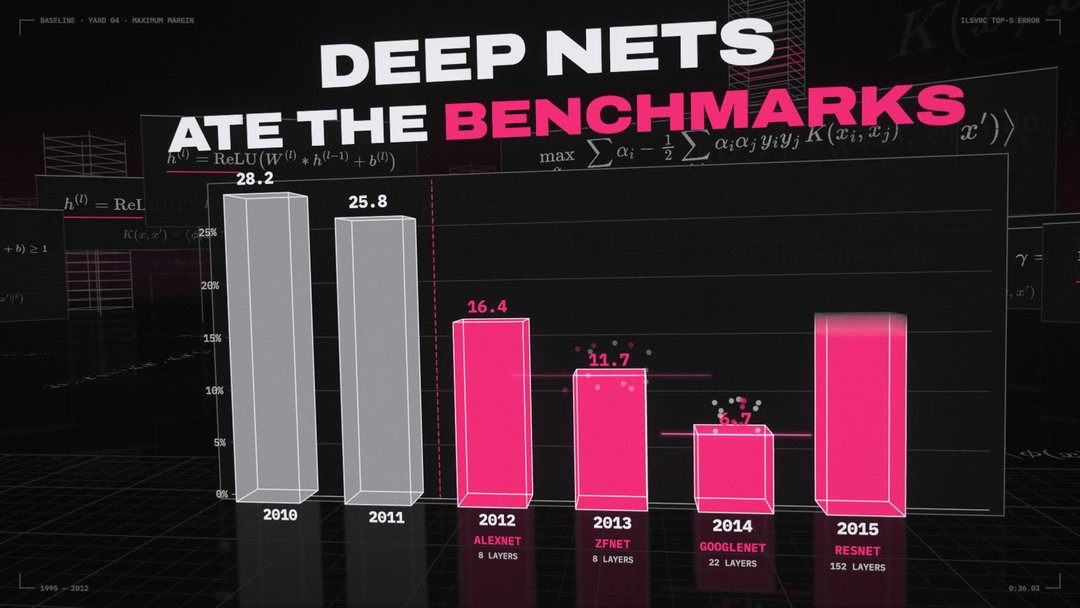

In [24]:
still(36.03)



<hr style="height:4px;border:0;background:#888;margin:2em 0 1em">

## 1.7 Depth is all you need: residual connections (2015)
If more layers mean richer re-representations, why not use 50 or 150? Because naive deep stacks are hard to optimize: the signal and gradient degrade layer by layer. **ResNet** (He et al., 2015) gave each block a shortcut, *output = x + f(x)*. A block only has to learn a *correction* to its input, and the gradient always has a clean path back through the `+`.

Test: classify two interleaved spirals with a 30-layer network, with and without the `x +`.

> **Predict first.** Same 30 layers, same data, same optimizer; the only difference is `h + f(h)` vs `f(h)`. What accuracy will the plain network reach? (Two classes, so chance is 50%.)



plain     final loss 0.693  acc 50.0%


residual  final loss 0.000  acc 100.0%


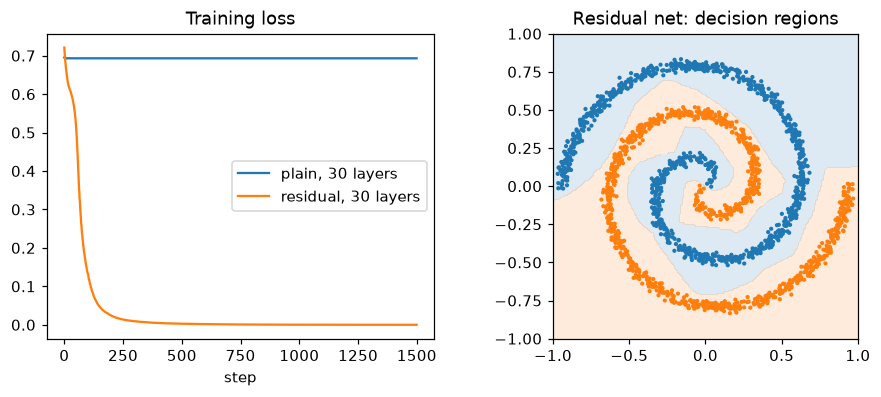

In [25]:
def spirals(n=1000, noise=0.2):
    t = np.sqrt(np.random.rand(n)) * 3 * np.pi
    a = np.c_[np.cos(t) * t, np.sin(t) * t] + np.random.randn(n, 2) * noise
    return torch.tensor(np.r_[a, -a] / 10, dtype=torch.float32), torch.tensor(np.r_[np.zeros(n), np.ones(n)]).long()

class DeepMLP(nn.Module):
    def __init__(self, depth, width, residual):
        super().__init__()
        self.inp, self.out, self.residual = nn.Linear(2, width), nn.Linear(width, 2), residual
        self.layers = nn.ModuleList(nn.Linear(width, width) for _ in range(depth))
    def forward(self, x):
        h = torch.relu(self.inp(x))
        for l in self.layers:
            h = h + torch.relu(l(h)) * 0.2 if self.residual else torch.relu(l(h))
        return self.out(h)

seed(0); Xs, ys = spirals()
curves = {}
for residual in (False, True):
    seed(1); m = DeepMLP(30, 32, residual)
    opt = torch.optim.Adam(m.parameters(), 1e-3); losses = []
    for step in range(1500):
        loss = F.cross_entropy(m(Xs), ys); opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
    curves['residual' if residual else 'plain'] = (losses, m)
    print(f"{'residual' if residual else 'plain   '}  final loss {losses[-1]:.3f}  acc {(m(Xs).argmax(1) == ys).float().mean():.1%}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.6))
a1.plot(curves['plain'][0], label='plain, 30 layers'); a1.plot(curves['residual'][0], label='residual, 30 layers')
a1.set(title='Training loss', xlabel='step'); a1.legend()
gx, gy = np.meshgrid(np.linspace(-1, 1, 200), np.linspace(-1, 1, 200))
with torch.no_grad():
    zz = curves['residual'][1](torch.tensor(np.c_[gx.ravel(), gy.ravel()], dtype=torch.float32)).argmax(1).reshape(gx.shape)
a2.contourf(gx, gy, zz, levels=1, colors=['C0', 'C1'], alpha=0.15); a2.scatter(*Xs.T, c=['C1' if t else 'C0' for t in ys], s=3)
a2.set(aspect='equal', title='Residual net: decision regions');



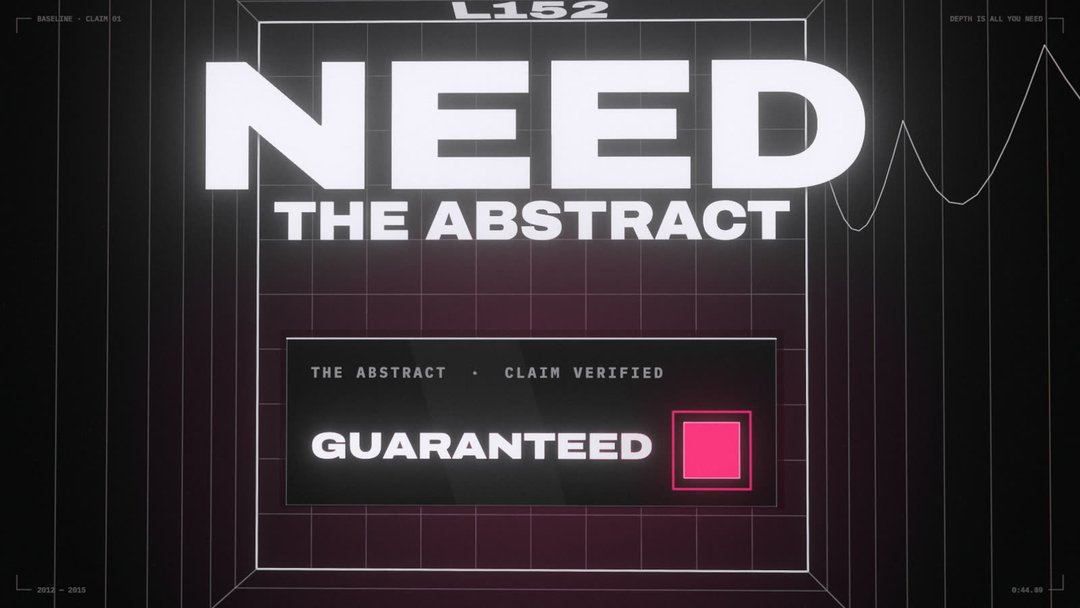

In [26]:
still(44.5)



<hr style="height:4px;border:0;background:#888;margin:2em 0 1em">

## 1.8 Frozen on the shelf



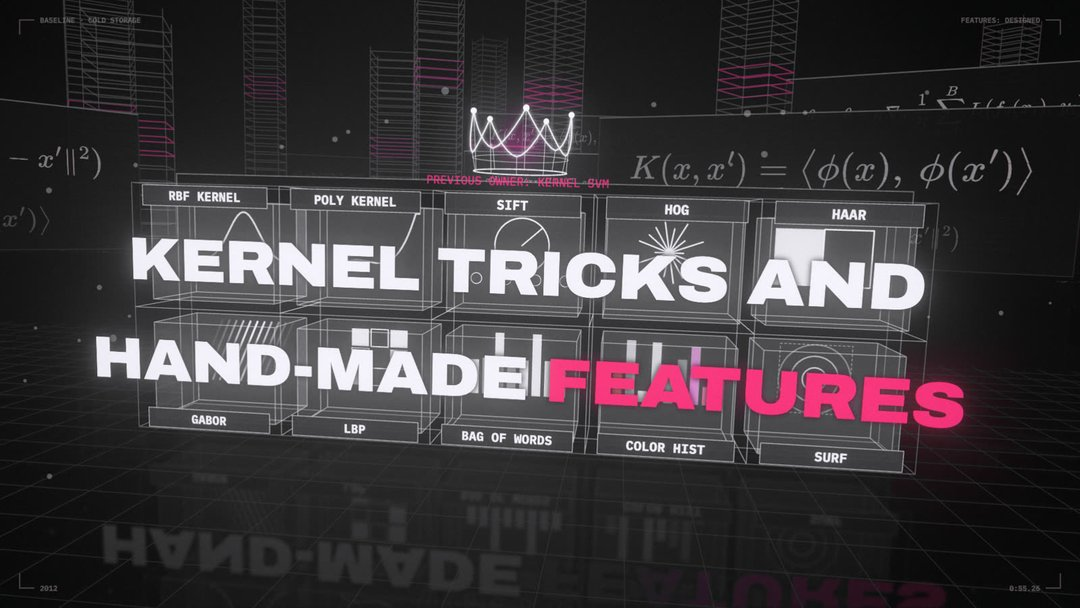

In [27]:
still(55.26)



By 2013 the kernel tricks and hand-made features were "frozen on the shelf": the network learned its own features. That pattern, a human-designed component replaced by a learned one, repeats through the rest of the song.



<hr style="height:4px;border:0;background:#888;margin:2em 0 1em">

### Checkpoint
1. Why can't a single perceptron learn XOR, and what does a hidden layer change?
2. What is backprop, in one sentence?
3. Why does a deep sigmoid stack learn slowly, and what two fixes did this module show?
4. In your CIFAR run, how big was the gap between HOG + SVM and the CNN? What would you expect if you doubled the training data for each?

<details><summary>Answers</summary>

1. No single line separates XOR's two classes. Hidden units each draw a line, and in their coordinates (OR, NAND) the points become separable by one line.
2. The chain rule, applied from the loss back through every layer, to get each weight's gradient.
3. Each sigmoid layer multiplies the gradient by at most ¼, so early layers get almost no signal. ReLU (slope 1, with a matching initialization) and residual connections (a clean `+` path back) fix it.
4. On the laptop tier the CNN wins by about 10–15 points. With more data the CNN keeps improving; HOG + SVM flattens out sooner, because its features can't get better.
</details>

**Next:** Module 2, where the input becomes a sequence.